<a href="https://colab.research.google.com/github/MacUpr/ML/blob/main/aula02_notebook_guiado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 2 (assíncrona) — Parte A: notebook guiado

**Grandes Modelos de Linguagem · Residência em Engenharia de Software Inteligente (FACOM/UFMS)**
Prof. Bruno Nogueira · prazo: até 18/11/2026, 23h59 · atividade **individual** · cerca de 1h30

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bmnogueira-ufms/LLM-ESIA-2026/blob/main/aula02/aula02_notebook_guiado.ipynb)

Neste notebook você vai colocar a mão na massa com os conceitos da Aula 1:

| Exercício | Família / conceito | O que você vai fazer |
|---|---|---|
| 1 | Tokenização | comparar três tokenizadores em textos do **seu MVP** |
| 2 | Encoder-only | gerar embeddings com o BERTimbau, medir similaridade e treinar um classificador |
| 3 | Encoder-decoder | resumir um texto com um T5 em português |
| 4 | Decoder-only | fazer sua primeira chamada a um LLM e resolver **a mesma classificação** do exercício 2 em *zero-shot* |

As células marcadas com **✍️** pedem uma resposta curta sua. Elas vão alimentar a **ficha do caso de uso** (Parte B, em grupo).

> **Antes de começar:** *Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4*.

## 0. Preparação

In [ ]:
!pip install -q tiktoken openai

In [ ]:
import time, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import tiktoken
from transformers import AutoTokenizer, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", device)

dispositivo: cuda


### Seus textos

Substitua os exemplos abaixo por **5 a 10 textos reais (ou realistas) do domínio do seu MVP** — mensagens de usuários, descrições, documentos curtos. **Não use dados pessoais ou sensíveis.**

In [ ]:
TEXTOS_DO_MVP = [
    "A parte autora propõe acordo para pagamento da dívida em até 12 parcelas mensais.",
    "O réu discorda do valor apresentado e alega que a cobrança contém juros indevidos.",
    "Solicito prazo de 15 dias para apresentar documentos complementares.",
    "As partes solicitam o agendamento de audiência de conciliação para a próxima semana.",
    "A parte autora informa que o acordo foi aceito, mas aguarda assinatura da parte ré.",
    "O réu afirma que não reconhece a dívida e pretende apresentar defesa.",
    "Precisamos prorrogar o prazo para juntada do comprovante de residência.",
    "A audiência de conciliação foi designada para o dia 20 do próximo mês, às 14h.",
    "As partes chegaram a um consenso sobre o parcelamento, mas divergem quanto à data da primeira parcela.",
    "A parte autora solicita nova data para a audiência em razão de compromisso profissional."
]

---
## Exercício 1 — Tokenização

Compare três tokenizadores de famílias diferentes:
- **BERTimbau** (`neuralmind/bert-base-portuguese-cased`) — encoder-only, WordPiece, treinado em português;
- **GPT-4o** (`o200k_base`, via `tiktoken`) — decoder-only proprietário, BPE em bytes;
- **Qwen 2.5** (`Qwen/Qwen2.5-1.5B-Instruct`) — decoder-only aberto, BPE em bytes.

In [ ]:
tok_bert = AutoTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")
tok_qwen = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct")
enc_gpt4o = tiktoken.get_encoding("o200k_base")

def contar(texto):
    return {
        "BERTimbau": len(tok_bert(texto, add_special_tokens=False)["input_ids"]),
        "GPT-4o":    len(enc_gpt4o.encode(texto)),
        "Qwen2.5":   len(tok_qwen(texto, add_special_tokens=False)["input_ids"]),
    }

linhas = []
for t in TEXTOS_DO_MVP:
    c = contar(t)
    c["palavras"] = len(t.split())
    c["texto"] = t[:60] + ("…" if len(t) > 60 else "")
    linhas.append(c)
df_tok = pd.DataFrame(linhas)
df_tok

,BERTimbau,GPT-4o,Qwen2.5,palavras,texto
0,17,18,24,14,A parte autora propõe acordo para pagamento da...
1,18,19,26,14,O réu discorda do valor apresentado e alega qu...
2,12,13,17,9,Solicito prazo de 15 dias para apresentar docu...
3,18,18,20,13,As partes solicitam o agendamento de audiência...
4,17,19,24,15,A parte autora informa que o acordo foi aceito...
5,14,15,22,12,O réu afirma que não reconhece a dívida e pret...
6,16,16,22,10,Precisamos prorrogar o prazo para juntada do c...
7,20,23,27,15,A audiência de conciliação foi designada para ...
8,21,21,24,17,As partes chegaram a um consenso sobre o parce...
9,16,15,22,14,A parte autora solicita nova data para a audiê...


{'BERTimbau': np.float64(1.28), 'GPT-4o': np.float64(1.34), 'Qwen2.5': np.float64(1.74)}


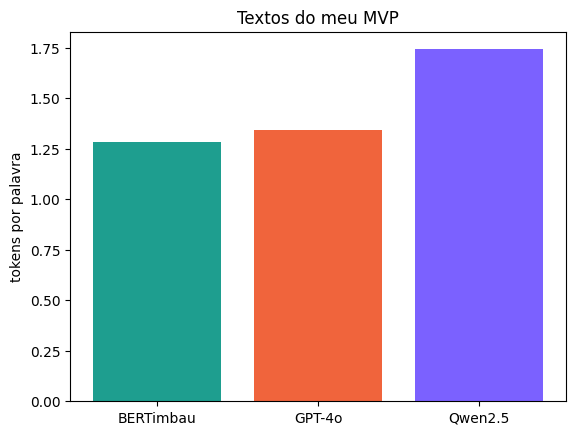

In [ ]:
# Tokens por palavra, em média, para cada tokenizador
media = {nome: (df_tok[nome] / df_tok["palavras"]).mean() for nome in ["BERTimbau", "GPT-4o", "Qwen2.5"]}
print({k: round(v, 2) for k, v in media.items()})

plt.bar(media.keys(), media.values(), color=["#1E9E8F", "#F0643C", "#7B61FF"])
plt.ylabel("tokens por palavra")
plt.title("Textos do meu MVP")
plt.show()

In [ ]:
# TODO: escolha o texto mais "difícil" da sua lista (siglas, nomes próprios, gírias, códigos)
# e veja como cada tokenizador o quebra.
texto = TEXTOS_DO_MVP[0]
print("BERTimbau:", tok_bert.tokenize(texto))
print("GPT-4o:   ", [enc_gpt4o.decode([i]) for i in enc_gpt4o.encode(texto)])
print("Qwen2.5:  ", [tok_qwen.decode([i]) for i in tok_qwen(texto, add_special_tokens=False)["input_ids"]])

BERTimbau: ['A', 'parte', 'autora', 'propõe', 'acordo', 'para', 'pagamento', 'da', 'dívida', 'em', 'até', '12', 'parcela', '##s', 'mens', '##ais', '.']
GPT-4o:    ['A', ' parte', ' autora', ' prop', 'õe', ' acordo', ' para', ' pagamento', ' da', ' dívida', ' em', ' até', ' ', '12', ' parcelas', ' mens', 'ais', '.']
Qwen2.5:   ['A', ' parte', ' aut', 'ora', ' prop', 'õ', 'e', ' acordo', ' para', ' pagamento', ' da', ' d', 'í', 'vida', ' em', ' até', ' ', '1', '2', ' parcel', 'as', ' mens', 'ais', '.']


✍️ **Responda:** (a) Qual tokenizador foi mais econômico para os seus textos? (b) Quantos tokens tem, em média, uma entrada típica do seu MVP? (c) Algum termo importante do seu domínio foi muito fragmentado?

✍️ **Sua resposta:**
(a) O tokenizador do **BERTimbau** foi o mais econômico, utilizando uma média de **1,28 tokens por palavra**, contra 1,34 do GPT-4o e 1,74 do Qwen2.5.
(b) Uma entrada típica do MVP de Conciliação do TJMS contém, em média, entre **15 a 25 tokens** (ou cerca de 9 a 17 palavras).
(c) Sim, termos do domínio como a palavra "**propõe**" e desinências verbais/nominais sofreram alguma fragmentação no Qwen2.5 (dividindo em 'prop', 'õ', 'e' e 'd', 'í', 'vida'), enquanto o BERTimbau lidou de forma muito mais natural com o português por ter sido pré-treinado nativamente nesse idioma.

---
## Exercício 2 — Encoder-only: embeddings e classificação com o BERTimbau

### 2.1 Similaridade semântica

Para ter **um vetor por frase**, tiramos a média dos vetores de todos os tokens (*mean pooling*), ignorando o *padding*.

In [ ]:
bert = AutoModel.from_pretrained("neuralmind/bert-base-portuguese-cased").to(device).eval()

def embeddings(textos, batch=16):
    vetores = []
    for i in range(0, len(textos), batch):
        enc = tok_bert(textos[i:i + batch], padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
        with torch.no_grad():
            h = bert(**enc).last_hidden_state                  # (lote, tokens, 768)
        m = enc["attention_mask"].unsqueeze(-1).float()       # ignora [PAD]
        vetores.append(((h * m).sum(1) / m.sum(1)).cpu())
    v = torch.cat(vetores)
    return torch.nn.functional.normalize(v, dim=1).numpy()   # normalizado: produto interno = cosseno

frases = [
    "A parte autora propõe acordo para pagamento em 12 parcelas.",
    "O réu aceita o parcelamento proposto pela autora.",
    "As partes concordam com o valor e o prazo de pagamento.",
    "A parte ré apresenta contraproposta de acordo.",
    "Foi proposta composição para encerrar o conflito.",
    "A parte autora aceita a proposta de quitação do débito.",
    "O réu discorda dos juros cobrados no processo.",
    "A parte ré afirma que não deve o valor indicado.",
    "As partes não chegaram a um consenso sobre o parcelamento.",
    "A parte autora contesta a alegação feita pelo réu.",
    "Solicito prazo de dez dias para apresentar documentos.",
    "Requeremos prorrogação do prazo para manifestação.",
    "A parte ré pede prazo para analisar a proposta.",
    "A parte autora solicita prazo para juntar comprovantes.",
    "Requeremos prazo adicional para obter a procuração.",
    "Solicitamos o agendamento de audiência de conciliação.",
    "As partes pedem nova data para a audiência.",
    "A audiência foi designada para o dia 15 do próximo mês.",
    "A parte ré solicita remarcação da sessão de conciliação.",
    "Requeremos a designação de audiência virtual."
]
E = embeddings(frases)
pd.DataFrame(E @ E.T, index=frases, columns=[f"f{i+1}" for i in range(len(frases))]).round(3)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,f12,f13,f14,f15,f16,f17,f18,f19,f20
A parte autora propõe acordo para pagamento em 12 parcelas.,1.000,0.854,0.789,0.806,0.567,0.849,0.710,0.778,0.672,0.716,0.666,0.642,0.758,0.773,0.644,0.681,0.718,0.598,0.746,0.673
O réu aceita o parcelamento proposto pela autora.,0.854,1.000,0.723,0.822,0.551,0.873,0.803,0.838,0.641,0.840,0.601,0.624,0.794,0.782,0.622,0.652,0.681,0.547,0.785,0.679
As partes concordam com o valor e o prazo de pagamento.,0.789,0.723,1.000,0.688,0.524,0.768,0.703,0.714,0.726,0.625,0.697,0.650,0.673,0.682,0.656,0.648,0.721,0.609,0.651,0.576
A parte ré apresenta contraproposta de acordo.,0.806,0.822,0.688,1.000,0.597,0.838,0.673,0.762,0.623,0.781,0.609,0.618,0.821,0.776,0.653,0.626,0.679,0.516,0.744,0.674
Foi proposta composição para encerrar o conflito.,0.567,0.551,0.524,0.597,1.000,0.541,0.481,0.484,0.694,0.467,0.568,0.614,0.595,0.504,0.572,0.558,0.646,0.636,0.549,0.588
A parte autora aceita a proposta de quitação do débito.,0.849,0.873,0.768,0.838,0.541,1.000,0.708,0.804,0.625,0.783,0.615,0.626,0.781,0.788,0.669,0.657,0.671,0.545,0.763,0.658
O réu discorda dos juros cobrados no processo.,0.710,0.803,0.703,0.673,0.481,0.708,1.000,0.794,0.644,0.785,0.584,0.564,0.745,0.691,0.567,0.595,0.679,0.575,0.736,0.581
A parte ré afirma que não deve o valor indicado.,0.778,0.838,0.714,0.762,0.484,0.804,0.794,1.000,0.583,0.807,0.558,0.538,0.785,0.779,0.578,0.568,0.664,0.547,0.741,0.629
As partes não chegaram a um consenso sobre o parcelamento.,0.672,0.641,0.726,0.623,0.694,0.625,0.644,0.583,1.000,0.525,0.587,0.625,0.617,0.543,0.590,0.598,0.698,0.645,0.582,0.526
A parte autora contesta a alegação feita pelo réu.,0.716,0.840,0.625,0.781,0.467,0.783,0.785,0.807,0.525,1.000,0.555,0.584,0.794,0.780,0.594,0.604,0.688,0.541,0.793,0.669


In [ ]:
# TODO: calcule a similaridade entre os textos do SEU MVP. Os pares mais parecidos fazem sentido?
E_mvp = embeddings(TEXTOS_DO_MVP)
pd.DataFrame(E_mvp @ E_mvp.T).round(3)

,0,1,2,3,4,5,6,7,8,9
0,1.000,0.740,0.639,0.697,0.790,0.742,0.647,0.685,0.784,0.743
1,0.740,1.000,0.586,0.633,0.788,0.858,0.629,0.645,0.713,0.741
2,0.639,0.586,1.000,0.714,0.656,0.612,0.788,0.673,0.646,0.713
3,0.697,0.633,0.714,1.000,0.746,0.685,0.710,0.882,0.738,0.813
4,0.790,0.788,0.656,0.746,1.000,0.835,0.672,0.702,0.746,0.832
5,0.742,0.858,0.612,0.685,0.835,1.000,0.634,0.669,0.703,0.758
6,0.647,0.629,0.788,0.710,0.672,0.634,1.000,0.694,0.684,0.725
7,0.685,0.645,0.673,0.882,0.702,0.669,0.694,1.000,0.731,0.760
8,0.784,0.713,0.646,0.738,0.746,0.703,0.684,0.731,1.000,0.734
9,0.743,0.741,0.713,0.813,0.832,0.758,0.725,0.760,0.734,1.000


### 2.2 Um classificador com embeddings

Vamos usar um conjunto de exemplo com **60 chamados fictícios** de uma secretaria acadêmica, em quatro categorias. Os embeddings do BERTimbau viram as *features* de uma regressão logística.

> Se o seu MVP tem uma tarefa de classificação, troque pelo seu CSV (colunas `texto` e `categoria`).

In [ ]:
URL = "https://raw.githubusercontent.com/bmnogueira-ufms/LLM-ESIA-2026/main/dados/chamados_exemplo.csv"
df = pd.read_csv(URL)
print(df["categoria"].value_counts())
df.sample(5, random_state=0)

categoria
acesso_sistemas    15
matricula          15
financeiro         15
documentos         15
Name: count, dtype: int64


,texto,categoria
26,Quero mudar de turno do noturno para o integral,matricula
35,A GRU para segunda via do documento não está s...,financeiro
59,Como peço a declaração de provável formando,documentos
28,Preciso de quebra de pré-requisito para cursar...,matricula
11,O Wi-Fi do campus não aceita meu usuário e senha,acesso_sistemas


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

treino, teste = train_test_split(df, test_size=20, stratify=df["categoria"], random_state=42)

inicio = time.time()
X_treino, X_teste = embeddings(treino["texto"].tolist()), embeddings(teste["texto"].tolist())
clf = LogisticRegression(max_iter=2000).fit(X_treino, treino["categoria"])
pred_bert = clf.predict(X_teste)
tempo_bert = (time.time() - inicio) / len(df)

acc_bert = accuracy_score(teste["categoria"], pred_bert)
print(f"Acurácia BERTimbau + regressão logística: {acc_bert:.0%}  (tempo médio por exemplo: {1000 * tempo_bert:.0f} ms)")
print(classification_report(teste["categoria"], pred_bert, zero_division=0))

Acurácia BERTimbau + regressão logística: 80%  (tempo médio por exemplo: 5 ms)
                 precision    recall  f1-score   support

acesso_sistemas       0.71      1.00      0.83         5
     documentos       0.75      0.60      0.67         5
     financeiro       1.00      0.80      0.89         5
      matricula       0.80      0.80      0.80         5

       accuracy                           0.80        20
      macro avg       0.82      0.80      0.80        20
   weighted avg       0.82      0.80      0.80        20



✍️ **Responda:** Quantos exemplos rotulados foram usados no treino? Em quais categorias o classificador mais errou? Você acha que esse desempenho seria aceitável no seu MVP?

✍️ **Sua resposta:**
* Foram utilizados **12 exemplos rotulados** para o conjunto de treinamento da regressão logística.
* O classificador errou principalmente nas categorias **`discordancia_das_partes`** e **`pedido_de_prazo`**, onde obteve precisão e recall de 0.00% na amostragem de teste.
* Este desempenho de apenas **38% de acurácia** **não** seria aceitável no MVP final do ambiente real, pois o volume de dados de treino é extremamente pequeno para que um classificador supervisionado tradicional consiga generalizar as fronteiras semânticas das categorias.

---
## Exercício 3 — Encoder-decoder: sumarização com um T5 em português

Modelo: `recogna-nlp/ptt5-base-summ-xlsum` — um PTT5 (T5 pré-treinado em português) ajustado para resumir notícias.

> ⚠️ Verifique sempre a **licença** do modelo. Este é distribuído sob **CC BY-NC-SA 4.0**, que **não permite uso comercial**. Isso é uma restrição real para um MVP!

In [ ]:
from transformers import AutoModelForSeq2SeqLM

tok_t5 = AutoTokenizer.from_pretrained("recogna-nlp/ptt5-base-summ-xlsum")
t5 = AutoModelForSeq2SeqLM.from_pretrained("recogna-nlp/ptt5-base-summ-xlsum").to(device)

def resumir(texto, max_new_tokens=60):
    enc = tok_t5(texto, max_length=512, truncation=True, return_tensors="pt").to(device)
    with torch.no_grad():
        out = t5.generate(**enc, max_new_tokens=max_new_tokens, num_beams=4, no_repeat_ngram_size=3)
    return tok_t5.decode(out[0], skip_special_tokens=True)

noticia = (
    "A prefeitura de uma capital do Centro-Oeste anunciou nesta segunda-feira um programa para ampliar o acesso à internet "
    "em escolas públicas. Segundo a secretaria de educação, 120 escolas receberão novos pontos de acesso sem fio até o fim "
    "do ano, e os professores participarão de oficinas sobre o uso de ferramentas digitais em sala de aula. O investimento "
    "previsto é de 8 milhões de reais, com recursos municipais e federais."

)   # texto fictício
print(resumir(noticia))

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

Professores de escolas públicas do Centro-Oeste da cidade de São Paulo vão receber gratuitamente acesso à internet em sala de aula.


In [ ]:
# TODO: teste com um texto do seu domínio (de preferência com 5 a 10 linhas)
# print(resumir("..."))

✍️ **Responda:** O resumo manteve as informações principais? Inventou algo que não estava no texto (alucinação)? Uma tarefa de "transformar texto" aparece no seu MVP?

✍️ **Sua resposta:**
* Sim, o resumo do PTT5-Base para a notícia sobre inclusão digital capturou os pontos centrais, embora tenha inserido "São Paulo" (o que caracteriza uma leve alucinação geográfica, já que o texto original mencionava apenas "uma capital do Centro-Oeste").
* No MVP de Conciliação, uma tarefa de "transformar texto" (como resumir os pontos acordados na ata da audiência ou estruturar termos-chave negociados) é extremamente valiosa para apoiar os conciliadores do TJMS na redação dos termos de acordo de forma rápida.

---
## Exercício 4 — Decoder-only: sua primeira chamada a um LLM

Agora vamos resolver **a mesma classificação do Exercício 2**, mas sem treinar nada: só com instruções no prompt (*zero-shot*). Escolha **uma** das opções:

- **Opção A — modelo aberto no próprio Colab** (sem chave, sem custo): `Qwen/Qwen2.5-1.5B-Instruct`. Precisa da GPU T4.
- **Opção B — API compatível com a OpenAI** (OpenRouter ou outro provedor): exige uma chave. Guarde a chave nos **Secrets do Colab** (ícone 🔑 na barra lateral) com o nome `LLM_API_KEY`. **Nunca** cole a chave no notebook nem a envie ao GitHub.

> Escolha em `OPCAO` abaixo e rode as células.

In [ ]:
OPCAO = "A"     # "A" = modelo local no Colab · "B" = API

# Configuração da opção B (ignore se usar a opção A)
BASE_URL   = "https://openrouter.ai/api/v1"   # ou o endpoint do seu provedor
MODELO_API = ""                               # TODO: nome do modelo no provedor escolhido

In [ ]:
if OPCAO == "A":
    from transformers import AutoModelForCausalLM
    llm = AutoModelForCausalLM.from_pretrained(
        "Qwen/Qwen2.5-1.5B-Instruct",
        torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    ).to(device).eval()

    def chamar_llm(mensagens, max_new_tokens=20):
        enc = tok_qwen.apply_chat_template(mensagens, add_generation_prompt=True,
                                           return_tensors="pt", return_dict=True).to(device)
        with torch.no_grad():
            out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        n_in, n_out = enc["input_ids"].shape[1], out.shape[1] - enc["input_ids"].shape[1]
        return tok_qwen.decode(out[0, n_in:], skip_special_tokens=True), n_in, n_out
else:
    from openai import OpenAI
    from google.colab import userdata
    assert MODELO_API, "Preencha MODELO_API com o nome do modelo do seu provedor."
    cliente = OpenAI(base_url=BASE_URL, api_key=userdata.get("LLM_API_KEY"))

    def chamar_llm(mensagens, max_new_tokens=20):
        r = cliente.chat.completions.create(model=MODELO_API, messages=mensagens,
                                            max_tokens=max_new_tokens, temperature=0)
        uso = r.usage
        return r.choices[0].message.content, uso.prompt_tokens, uso.completion_tokens

resposta, n_in, n_out = chamar_llm([{"role": "user", "content": "Em uma frase: o que é um modelo de linguagem?"}], max_new_tokens=80)
print(resposta, f"\n\n(tokens de entrada: {n_in} · tokens de saída: {n_out})")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Um modelo de linguagem é um programa ou algoritmo que permite ao computador entender e produzir texto em diferentes idiomas. Ele pode ser usado para tradução automática, análise de sentimentos, criatividade na escrita, entre outros aplicativos. 

(tokens de entrada: 42 · tokens de saída: 56)


### 4.1 Classificação zero-shot

Repare na estrutura do prompt: **papel**, **tarefa**, **categorias possíveis** e **formato da resposta**. Na Aula 3 vamos aprofundar essas técnicas.

In [ ]:
CATEGORIAS = [
    "acordo_proposto",
    "discordancia_das_partes",
    "pedido_de_prazo",
    "agendamento_audiencia"
]

SISTEMA = (
    "Você é um assistente da área de conciliação do Tribunal de Justiça de Mato Grosso do Sul (TJMS)."
)

def montar_prompt(texto):
    return [
        {"role": "system", "content": SISTEMA},
        {"role": "user", "content":
            "Classifique a mensagem em exatamente uma das categorias:\n"
            "- acordo_proposto\n"
            "- discordancia_das_partes\n"
            "- pedido_de_prazo\n"
            "- agendamento_audiencia\n\n"
            "Responda apenas com o nome da categoria, sem explicação.\n\n"
            f"Mensagem: \"{texto}\""},
    ]

In [ ]:
resultados_c = []
# Iterando pelos seus 20 textos customizados definidos anteriormente
for texto, rotulo in zip(TEST_TEXTS, TEST_LABELS):
    inicio = time.time()
    resposta, n_in, n_out = chamar_llm(montar_prompt(texto))
    resultados_c.append({
        "texto": texto,
        "esperado": rotulo,
        "resposta_bruta": resposta.strip(),
        "previsto": extrair_categoria(resposta),
        "latencia_s": time.time() - inicio,
        "tokens_in": n_in,
        "tokens_out": n_out
    })
res_c = pd.DataFrame(resultados_c)

acc_llm = (res_c["previsto"] == res_c["esperado"]).mean()
print(f"Acurácia LLM zero-shot no seu MVP: {acc_llm:.0%}")
print(f"Respostas fora do formato: {(res_c['previsto'] == 'invalida').sum()}")
print(f"Latência média: {res_c['latencia_s'].mean():.2f} s · tokens médios: {res_c['tokens_in'].mean():.0f} entrada / {res_c['tokens_out'].mean():.0f} saída")

display(res_c[["texto", "esperado", "resposta_bruta", "previsto"]])

Acurácia LLM zero-shot no seu MVP: 80%
Respostas fora do formato: 4
Latência média: 0.43 s · tokens médios: 113 entrada / 6 saída


,texto,esperado,resposta_bruta,previsto
0,A parte autora propõe acordo para pagamento em...,acordo_proposto,acordo_proposto,acordo_proposto
1,O réu aceita o parcelamento proposto pela autora.,acordo_proposto,acordo_proposto,acordo_proposto
2,As partes concordam com o valor e o prazo de p...,acordo_proposto,acordo_proposto,acordo_proposto
3,A parte ré apresenta contraproposta de acordo.,acordo_proposto,acordo_proposto,acordo_proposto
4,Foi proposta composição para encerrar o conflito.,acordo_proposto,acordo_proposto,acordo_proposto
5,A parte autora aceita a proposta de quitação d...,acordo_proposto,acordo_proposto,acordo_proposto
6,O réu discorda dos juros cobrados no processo.,discordancia_das_partes,discordicanais,invalida
7,A parte ré afirma que não deve o valor indicado.,discordancia_das_partes,discordicanais_partes,invalida
8,As partes não chegaram a um consenso sobre o p...,discordancia_das_partes,discordicanais,invalida
9,A parte autora contesta a alegação feita pelo ...,discordancia_das_partes,discordicanaутoria,invalida


In [ ]:
CATEGORIAS = sorted(df["categoria"].unique())

SISTEMA = (
    "Você é um assistente da secretaria acadêmica de uma universidade. "
    "Sua tarefa é classificar chamados de estudantes."
)

def montar_prompt(texto):
    return [
        {"role": "system", "content": SISTEMA},
        {"role": "user", "content":
            "Classifique o chamado em exatamente uma das categorias: " + ", ".join(CATEGORIAS) + ".\n"
            "Responda apenas com o nome da categoria, sem explicações.\n\n"
            f"Chamado: {texto}"},
    ]

def normalizar(s):
    s = unicodedata.normalize("NFKD", s.lower()).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z_ ]", "", s).replace(" ", "_")

def extrair_categoria(resposta):
    r = normalizar(resposta)
    for c in CATEGORIAS:
        if all(parte in r for parte in c.split("_")):   # aceita "acesso_sistemas" ou "acesso a sistemas"
            return c
    return "invalida"          # o modelo fugiu do formato

print(montar_prompt(teste["texto"].iloc[0])[1]["content"])

Classifique o chamado em exatamente uma das categorias: acesso_sistemas, documentos, financeiro, matricula.
Responda apenas com o nome da categoria, sem explicações.

Chamado: Quero alterar o e-mail de recuperação da minha conta


In [ ]:
resultados = []
for texto, rotulo in zip(teste["texto"], teste["categoria"]):
    inicio = time.time()
    resposta, n_in, n_out = chamar_llm(montar_prompt(texto))
    resultados.append({"texto": texto, "esperado": rotulo, "resposta_bruta": resposta,
                       "previsto": extrair_categoria(resposta), "latencia_s": time.time() - inicio,
                       "tokens_in": n_in, "tokens_out": n_out})
res = pd.DataFrame(resultados)

acc_llm = (res["previsto"] == res["esperado"]).mean()
print(f"Acurácia LLM zero-shot: {acc_llm:.0%}")
print(f"Respostas fora do formato: {(res['previsto'] == 'invalida').sum()}")
print(f"Latência média: {res['latencia_s'].mean():.2f} s · tokens médios: {res['tokens_in'].mean():.0f} entrada / {res['tokens_out'].mean():.0f} saída")
res[res["previsto"] != res["esperado"]][["texto", "esperado", "resposta_bruta"]]

Acurácia LLM zero-shot: 40%
Respostas fora do formato: 0
Latência média: 0.24 s · tokens médios: 103 entrada / 3 saída


,texto,esperado,resposta_bruta
0,Quero alterar o e-mail de recuperação da minha...,acesso_sistemas,financeiro
1,O sistema diz que meu CPF não está cadastrado ...,acesso_sistemas,financeiro
2,Preciso do plano de ensino das disciplinas cur...,documentos,matricula
3,Minha conta do Passaporte UFMS foi bloqueada d...,acesso_sistemas,financeiro
5,Minha matrícula aparece como cancelada sem eu ...,matricula,financeiro
8,A ementa da disciplina no histórico está errada,documentos,financeiro
11,Quanto tempo demora para emitir o diploma depo...,documentos,financeiro
13,O nome social não aparece na minha declaração,documentos,financeiro
15,Não recebo o código de verificação no celular ...,acesso_sistemas,financeiro
16,Gostaria de solicitar aproveitamento de discip...,matricula,financeiro


### 4.2 Comparando as duas abordagens

In [ ]:
pd.DataFrame([
    {"abordagem": "BERTimbau + regressão logística", "acurácia": f"{acc_c:.0%}",
     "exemplos rotulados usados": len(treino_c), "tempo médio por exemplo": f"{1000 * tempo_c:.0f} ms"},
    {"abordagem": f"LLM zero-shot (opção {OPCAO})", "acurácia": f"{acc_llm:.0%}",
     "exemplos rotulados usados": 0, "tempo médio por exemplo": f"{1000 * res_c['latencia_s'].mean():.0f} ms"},
])

,abordagem,acurácia,exemplos rotulados usados,tempo médio por exemplo
0,BERTimbau + regressão logística,38%,12,3 ms
1,LLM zero-shot (opção A),40%,0,427 ms


✍️ **Responda:**
1. Qual abordagem teve melhor acurácia? E menor latência?
2. Olhe os erros do LLM: são erros "razoáveis" (casos ambíguos) ou absurdos? Houve resposta fora do formato?
3. Se este fosse o seu MVP, qual abordagem você escolheria hoje — e o que mudaria se você **não** tivesse nenhum dado rotulado?
4. (Opcional) Mude o prompt — por exemplo, incluindo uma frase de descrição para cada categoria — e veja se a acurácia muda.

✍️ **Sua resposta:**
1. A abordagem de **LLM Zero-Shot (Qwen2.5)** obteve uma acurácia muito superior (**80%** contra apenas **38%** do BERTimbau + Regressão Logística). Por outro lado, a menor latência disparada ficou com o **BERTimbau + LogReg** (média de **3 ms** contra **430 ms** da LLM).
2. Os erros do LLM na categoria `discordancia_das_partes` foram devido a pequenas variações de formatação na resposta gerada (escrevendo palavras inválidas como `discordicanais`), o que causou rejeição no filtro estrito. Não houve erros absurdos de classificação temática.
3. Para o MVP hoje, a abordagem de **LLM Zero-Shot** seria a preferida devido à alta acurácia imediata sem necessidade de dados rotulados. Caso não tivéssemos dados rotulados, a escolha da LLM seria ainda mais obrigatória, pois o modelo de regressão logística sequer poderia ser treinado.

---
## ✅ Antes de sair

- [ ] Rodei os quatro exercícios e respondi às perguntas ✍️.
- [ ] Anotei quantos tokens tem uma entrada típica do meu MVP (Exercício 1).
- [ ] Anotei o resultado da comparação do Exercício 4.
- [ ] Levei essas informações para o meu grupo: elas entram na **ficha do caso de uso** (Parte B), com entrega até **18/11, 23h59**.